In [ ]:
import os
import sys

sys.path.append(os.path.abspath(os.path.join("..")))
import uuid

from IPython.display import Image, display
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.runnables.config import RunnableConfig
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.store.base import BaseStore
from langgraph.store.memory import InMemoryStore

from utils.models import ModelName, Models, Trace


In [2]:
trace = Trace()
models = Models()
model_name = ModelName.NEMOTRON_3_5_SUPER_VL_120b_a12b.value
nvidia_model = models.create_nvidia_model(model_name)


Creating model nvidia/nemotron-3.5-super-vl-120b-a12b


In [4]:
in_memory_store = InMemoryStore()

In [ ]:
user_id = "1"
namespace = (user_id, "memory")
key = str(uuid.uuid4())
value = {"preferences": "I like pizza"}
in_memory_store.put(namespace=namespace, key=key, value=value)

In [ ]:
memory = in_memory_store.search(namespace)
memory[0].dict()

{'namespace': ['1', 'memory'],
 'key': '39fc84bd-37ea-4c8a-b0eb-329d99c723b0',
 'value': {'preferences': 'I like pizza'},
 'created_at': '2026-11-05T15:54:51.714012+00:00',
 'updated_at': '2026-11-05T15:54:51.714016+00:00',
 'score': None}

In [2]:
llm_model_instructions = """You are a helpful assistant with memory that provides relevant information about the user.
If you have memory about this user, personalize your responses
Here is the memory:{memory}
"""

In [3]:
create_memory_instructions = """You are collecting information about the user to personalize your responses 
Current user information:{memory}

Instructions:
1.Review the chat history carefully.
2. Identify useful information about the users such as:
    - personal details like name,location,occupation
    - Preferences such as likes and dislikes
    - Interests and hobbies
    - Past experiences
    - Goals and future plans
3.When you have new information, merge with the existing memory 
4. Format the memory as a clear,bulleted list 
5. If new information conflicts with the existing memory, only keep the most recent ones
6.All the information should be only facts stated by the user, do not bring outside information,assumptions or inferences 
Based on the chat history, please update the user information.
"""

In [15]:
def call_llm(state: MessagesState, config: RunnableConfig, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    namespace = ("memory", user_id)
    key = "user_memory"
    existing_memory = store.get(namespace, key)

    if existing_memory:
        existing_memory_content = existing_memory.value.get("memory")
    else:
        existing_memory_content = "No existing memory found"

    sys_msg = llm_model_instructions.format(memory=existing_memory_content)

    response = nvidia_model.invoke([SystemMessage(sys_msg)] + state["messages"])

    return {"messages": response}


In [16]:
def write_memory(state: MessagesState, config: RunnableConfig, store: BaseStore):
    user_id = config["configurable"]["user_id"]
    namespace = ("memory", user_id)
    key = "user_memory"
    existing_memory = store.get(namespace, key)

    if existing_memory:
        existing_memory_content = existing_memory.value.get("memory")
    else:
        existing_memory_content = "No existing memory found"

    sys_msg = create_memory_instructions.format(memory=existing_memory_content)

    new_memory = nvidia_model.invoke([SystemMessage(sys_msg)] + state["messages"])
    store.put(namespace, key, {"memory": new_memory})

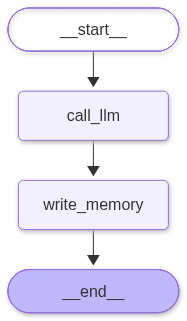

In [19]:
builder = StateGraph(MessagesState)
builder.add_node("call_llm", call_llm)
builder.add_node("write_memory", write_memory)
builder.add_edge(START, "call_llm")
builder.add_edge("call_llm", "write_memory")
builder.add_edge("write_memory", END)
across_thread_memory = InMemoryStore()
graph = builder.compile(checkpointer=MemorySaver(), store=across_thread_memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
thread: RunnableConfig = {"configurable": {"thread_id": "1", "user_id": "1"}}
input_msg = [HumanMessage("Hi, I am Jason")]

for event in graph.stream({"messages": input_msg}, config=thread, stream_mode="values"):
    event["messages"][-1].pretty_print()


================================ Human Message =================================

Hi, I am Jason
================================== Ai Message ==================================

Hi Jason! Nice to meet you. I don't have any previous memory of our conversations yet, so this is a fresh start. How can I help you today?


In [22]:
input_msg = [HumanMessage("I like hiking around San Francisco ")]


In [24]:
for event in graph.stream({"messages": input_msg}, config=thread, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

I like hiking around San Francisco 
================================== Ai Message ==================================

That's great, Jason! San Francisco has some fantastic hiking spots with amazing views. A few favorites include:

- **Lands End** – coastal trails with Golden Gate Bridge views
- **Twin Peaks** – great for city skyline panoramas
- **Mount Sutro** – a quieter forested escape right in the city
- **Muir Woods** (just north of SF) – redwood groves and shaded trails

Are you looking for new trail recommendations, or do you already have a favorite spot you like to return to?


In [25]:
user_id = "1"
namespace = ("memory", user_id)
existing_memory = across_thread_memory.get(namespace, key="user_memory")
existing_memory.dict()

{'namespace': ['memory', '1'],
 'key': 'user_memory',
 'value': {'memory': AIMessage(content='It’s great that you enjoy hiking around San Francisco! Are you looking for new trail recommendations, or do you already have a favorite spot you like to return to?\n\n**User Information:**\n- Name: Jason\n- Location: San Francisco\n- Interest: Hiking around San Francisco', additional_kwargs={'reasoning_content': 'The user said "I am Jason" and "I like hiking around San Francisco". The task says: Review chat history, identify useful information, merge with existing memory, format as clear bulleted list, only keep most recent if conflict, only facts stated by user (no assumptions/inferences). But the current prompt below seems to be just "Hello" again (actually I see the user message is "Hello" in the latest turn? Let\'s look carefully.)\n\nThe conversation provided:\n- Current user information block shows assistant said "Got it, Jason..." with reasoning content.\n- Instructions about updating u

In [27]:
thread: RunnableConfig = {"configurable": {"thread_id": "2", "user_id": "1"}}
input_msg = [
    HumanMessage(
        content="I am looking for hiking trails that would take more than a day"
    )
]
for event in graph.stream({"messages": input_msg}, thread, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

I am looking for hiking trails that would take more than a day
================================== Ai Message ==================================

Hey Jason! Since you’re based in San Francisco and want trips that go beyond a single day, you’ve got some fantastic multi-day backpacking options within a few hours’ drive. Here are a few worth considering:

### 1. Point Reyes National Seashore
- **Distance from SF:** ~1 hour north
- **Trip length:** 1–3 nights
- **Highlights:** Coastal bluffs, elephant seals, Alamere Falls (a rare tidefall), and beach camping.
- **Camping:** Backcountry campgrounds like Wildcat Camp, Glen Camp, and Sky Camp. Permits are required and can be competitive in peak season.

### 2. Henry W. Coe State Park
- **Distance from SF:** ~1.5–2 hours south (near Morgan Hill)
- **Trip length:** 1–2 nights
- **Highlights:** One of the largest state parks in Northern California, with rolling oak 